<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week5/lesson16/Lesson16_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 16 — Probability Rules: Events, Conditioning and Detection

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 5 — Probability\
**Lesson:** Lesson 16\
**Notebook type:** Teaching notebook

> *"A detector that always says yes never misses anything."*

---

### From fitting to chance

Weeks 1 to 4 treated data as fixed numbers to fit. But a mouse shown the same grating twice does not respond the same way twice, and a neuron shown the same stimulus twice does not fire the same number of spikes. Week 5 builds the language for this variability, starting with its grammar: **events** and the **rules of probability**.

We will see:
1. how to describe outcomes and events as sets, and compute with them as Boolean arrays;
2. the three **axioms** of probability, and the rules that follow from them;
3. **joint, marginal and conditional** probabilities, and why $P(A\mid B) \ne P(B\mid A)$;
4. **independence**, conditional independence, and the **law of total probability**, including how averaging over groups can reverse a comparison;
5. **confusion matrices**: hits, misses, false alarms, sensitivity, specificity and precision, all as conditional probabilities;
6. how moving a **decision threshold** trades hits against false alarms.

The mini-lab uses a Neuropixels session from a mouse performing a visual decision task ([Steinmetz et al., 2019](https://doi.org/10.1038/s41586-019-1787-x)): we tabulate what the mouse saw against what it did, and then build a detector of right-side gratings from 66 primary visual cortex neurons.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-15.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
LINESTYLES = ['-', '--', ':', '-.']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Sliders are pre-computed frames, so they work offline and in a static viewer.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-15.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation and Retrieval: Is This a Good Detector?**

In the mini-lab session, a mouse was shown a grating on 232 trials and turned the wheel on 218 of them. On 108 trials there was no grating at all, and it turned the wheel on 58 of those.

- Fraction of grating trials with a turn: $218/232 \approx 0.94$.
- Fraction of blank trials with a turn: $58/108 \approx 0.54$.

**Prediction before reading on:** is "turns the wheel on 94% of grating trials" evidence that the mouse detects gratings well? What would a mouse that turned the wheel on *every* trial score on that number?

It would score 100%. The first number alone says nothing about detection; it has to be read **together with** the second. Both are **conditional probabilities** (the probability of a turn *given* a grating, and *given* no grating), and the whole of this lesson is about computing, combining and not confusing such quantities.

In [3]:
hits, n_present = 218, 232
false_alarms, n_absent = 58, 108
print(f"P(turn | grating)    = {hits}/{n_present} = {hits / n_present:.3f}")
print(f"P(turn | no grating) = {false_alarms}/{n_absent} = {false_alarms / n_absent:.3f}")
print(f"a mouse that always turns:  P(turn | grating) = 1.000,  P(turn | no grating) = 1.000")

P(turn | grating)    = 218/232 = 0.940
P(turn | no grating) = 58/108 = 0.537
a mouse that always turns:  P(turn | grating) = 1.000,  P(turn | no grating) = 1.000


# **Part 1: Outcomes, Events and Event Algebra**

- An **experiment** is a procedure whose result is not known in advance: one trial of a task.
- The **sample space** $\Omega$ is the set of all possible **outcomes**. For one trial, an outcome could be the pair (left contrast, right contrast, wheel response).
- An **event** is a subset of $\Omega$: a statement about the outcome that is either true or false on each trial, such as "a grating appeared on the right" ($R$) or "the mouse turned the wheel" ($G$, for go).

Events combine like sets:

| Operation | Notation | Meaning |
|---|---|---|
| complement | $A^{c}$ | not $A$ |
| intersection | $A \cap B$ | $A$ and $B$ |
| union | $A \cup B$ | $A$ or $B$ (or both) |
| difference | $A \setminus B$ | $A$ but not $B$ |
| disjoint | $A \cap B = \varnothing$ | cannot both happen |

In NumPy, with events stored as Boolean arrays: complement `~A`, intersection `A & B`, union `A | B`, difference `A & ~B`, and "disjoint" is `not np.any(A & B)`.

**De Morgan's laws:** $(A \cup B)^{c} = A^{c} \cap B^{c}$ and $(A \cap B)^{c} = A^{c} \cup B^{c}$.

With $n$ recorded trials, an event is stored as a **Boolean array of shape `(n,)`**, one entry per trial, `True` where the event happened. All arrays describing the same trials must be aligned: entry `i` of every array refers to trial `i`.

We simulate a toy session of 2,000 trials (the generating probabilities are invented, so we know the truth): on each trial a grating may appear on the left, on the right, on both sides or on neither, and the mouse may turn the wheel.

In [4]:
n_sim = 2000
contrast_levels = np.array([0.0, 0.25, 1.0])                              # possible contrasts on each side
p_levels = np.array([0.5, 0.25, 0.25])                                    # probability of each contrast, chosen independently per side
cL = RNG.choice(contrast_levels, size=n_sim, p=p_levels)                 # (2000,) left contrast, 0-1
cR = RNG.choice(contrast_levels, size=n_sim, p=p_levels)                 # (2000,) right contrast, 0-1
p_go_true = np.where((cL > 0) | (cR > 0), 0.9, 0.3)                      # (2000,) invented probability of a wheel turn
go_sim = RNG.random(n_sim) < p_go_true                                    # (2000,) True where the mouse turned

L_ev, R_ev = cL > 0, cR > 0                                               # events as Boolean arrays, shape (2000,)
print("shapes:", L_ev.shape, R_ev.shape, go_sim.shape, "  dtype:", L_ev.dtype)
print("first 8 trials  L:", L_ev[:8].astype(int), " R:", R_ev[:8].astype(int), " L and R:", (L_ev & R_ev)[:8].astype(int), " L or R:", (L_ev | R_ev)[:8].astype(int))
print("De Morgan 1 holds on every trial:", np.array_equal(~(L_ev | R_ev), ~L_ev & ~R_ev))
print("De Morgan 2 holds on every trial:", np.array_equal(~(L_ev & R_ev), ~L_ev | ~R_ev))
print("L and 'L but not R' and 'L and R': the last two are disjoint and together make L:",
      not np.any((L_ev & ~R_ev) & (L_ev & R_ev)), np.array_equal((L_ev & ~R_ev) | (L_ev & R_ev), L_ev))

shapes: (2000,) (2000,) (2000,)   dtype: bool
first 8 trials  L: [1 0 1 1 0 1 1 1]  R: [1 0 1 1 0 1 0 0]  L and R: [1 0 1 1 0 1 0 0]  L or R: [1 0 1 1 0 1 1 1]
De Morgan 1 holds on every trial: True
De Morgan 2 holds on every trial: True
L and 'L but not R' and 'L and R': the last two are disjoint and together make L: True True


Events are **set statements about outcomes**, so these identities hold trial by trial, exactly, not just on average. Note the last line: $A$ splits into the two disjoint pieces $A \cap B^{c}$ and $A \cap B$. That decomposition will give us the law of total probability in Part 4.

# **Part 2: The Axioms of Probability and What Follows**

A **probability** assigns a number $P(A)$ to every event $A$ such that (Kolmogorov's axioms):
1. **non-negativity:** $P(A) \ge 0$;
2. **normalisation:** $P(\Omega) = 1$;
3. **additivity:** if $A_1, A_2, \dots$ are pairwise disjoint, $P(A_1 \cup A_2 \cup \cdots) = P(A_1) + P(A_2) + \cdots$.

Everything else is derived. For example, $A$ and $A^{c}$ are disjoint with union $\Omega$, so $P(A) + P(A^{c}) = 1$. Similarly:

| Rule | Statement | Why |
|---|---|---|
| complement | $P(A^{c}) = 1 - P(A)$ | additivity + normalisation |
| empty event | $P(\varnothing) = 0$ | complement of $\Omega$ |
| monotonicity | $A \subseteq B \Rightarrow P(A) \le P(B)$ | $B = A \cup (B \setminus A)$, disjoint |
| bound | $0 \le P(A) \le 1$ | monotonicity with $A \subseteq \Omega$ |
| inclusion–exclusion | $P(A \cup B) = P(A) + P(B) - P(A \cap B)$ | $A \cup B = A \cup (B \setminus A)$ and $B = (B \setminus A) \cup (A \cap B)$, both disjoint |
| union bound | $P(A \cup B) \le P(A) + P(B)$ | $P(A \cap B) \ge 0$ |

**Probability as long-run frequency.** For repeatable trials, $P(A)$ is the proportion of trials on which $A$ happens in the long run. With finite data we compute the **empirical proportion** $\hat P(A) = \#\{\text{trials with } A\}/n$, which in NumPy is `A.mean()` for a Boolean array `A`. Empirical proportions satisfy all the axioms exactly (they are a probability on the recorded trials), but they are **estimates** of the long-run probabilities and fluctuate from session to session.

In [5]:
def prob(event):
    # Empirical probability of an event stored as a Boolean array of shape (n,).
    event = np.asarray(event)
    if event.dtype != bool or event.ndim != 1:
        raise ValueError("an event must be a 1-D Boolean array, one entry per trial")
    return event.mean()

pL, pR = prob(L_ev), prob(R_ev)
pLR, pLorR = prob(L_ev & R_ev), prob(L_ev | R_ev)
print(f"P(L) = {pL:.4f}   P(R) = {pR:.4f}   P(L and R) = {pLR:.4f}   P(L or R) = {pLorR:.4f}")
print(f"inclusion-exclusion: P(L) + P(R) - P(L and R) = {pL + pR - pLR:.4f}  (equal to P(L or R): {np.isclose(pL + pR - pLR, pLorR)})")
print(f"naive sum P(L) + P(R) = {pL + pR:.4f} overcounts the trials with gratings on both sides")
print(f"complement: P(no grating) = {prob(~(L_ev | R_ev)):.4f} = 1 - P(L or R) = {1 - pLorR:.4f}")
print(f"true values from the simulation's design: P(L) = P(R) = 0.5, P(L and R) = 0.25, P(L or R) = 0.75")

P(L) = 0.4960   P(R) = 0.4925   P(L and R) = 0.2455   P(L or R) = 0.7430
inclusion-exclusion: P(L) + P(R) - P(L and R) = 0.7430  (equal to P(L or R): True)
naive sum P(L) + P(R) = 0.9885 overcounts the trials with gratings on both sides
complement: P(no grating) = 0.2570 = 1 - P(L or R) = 0.2570
true values from the simulation's design: P(L) = P(R) = 0.5, P(L and R) = 0.25, P(L or R) = 0.75


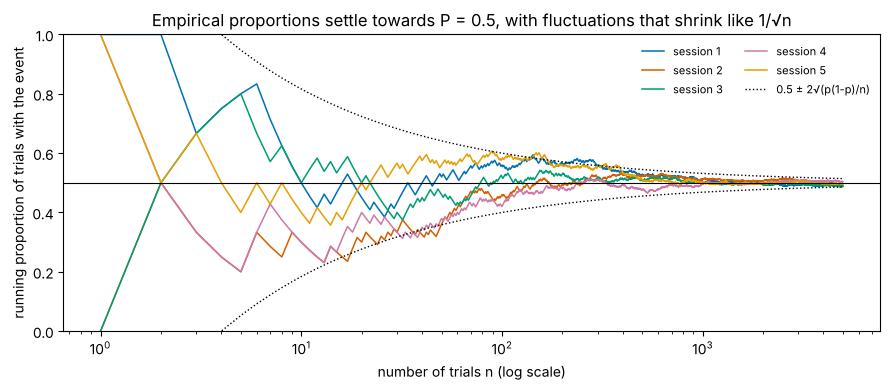

In [6]:
# Long-run frequency: running proportion of the event "grating on the right" in five independent simulated sessions.
n_long = 5000
fig, ax = plt.subplots(figsize=(9, 4))
trials = np.arange(1, n_long + 1)
for s in range(5):
    occurs = RNG.random(n_long) < 0.5                                       # (5000,) event with true probability 0.5
    ax.plot(trials, np.cumsum(occurs) / trials, color=PALETTE[s], lw=1.1, label=f'session {s + 1}')
ax.plot(trials, 0.5 + 2 * np.sqrt(0.25 / trials), 'k:', lw=1, label='0.5 ± 2√(p(1-p)/n)')
ax.plot(trials, 0.5 - 2 * np.sqrt(0.25 / trials), 'k:', lw=1)
ax.axhline(0.5, color='black', lw=0.8)
ax.set_xscale('log'); ax.set_ylim(0, 1)
ax.set_xlabel('number of trials n (log scale)'); ax.set_ylabel('running proportion of trials with the event')
ax.set_title('Empirical proportions settle towards P = 0.5, with fluctuations that shrink like 1/√n')
ax.legend(fontsize=8, ncol=2, frameon=False)
plt.tight_layout(); plt.show()

After 20 trials a session can easily show 0.35 or 0.65; after 5,000 the proportions agree to about $\pm0.014$. The dotted envelope, $\pm2\sqrt{p(1-p)/n}$, is the typical size of these fluctuations; Lesson 17 derives it. For now the message is practical: **every probability you compute from data carries sampling noise**, and comparisons between two estimated probabilities must be read with that in mind.

> **Common error.** Adding probabilities of events that can happen together. "Grating on the left" and "grating on the right" are not disjoint (both-sides trials exist), so $P(L \cup R) \ne P(L) + P(R)$. Additivity needs disjoint events.

# **Part 3: Joint, Marginal and Conditional Probabilities**

Take two **categorical variables** recorded on every trial, such as the stimulus condition $X$ and the response $Y$. Their **joint probability table** has one entry per combination,

$$p_{ij} = P(X = x_i,\ Y = y_j),\qquad \sum_i\sum_j p_{ij} = 1,$$

stored as an array of shape `(n_x_levels, n_y_levels)`: **rows index $X$, columns index $Y$**.

- **Marginal** probabilities come from summing out the other variable: $P(X = x_i) = \sum_j p_{ij}$ (row sums, `axis=1`) and $P(Y = y_j) = \sum_i p_{ij}$ (column sums, `axis=0`).
- The **conditional probability** of $A$ given $B$, defined when $P(B) > 0$, is

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}.$$

Conditioning on $B$ means **restricting attention to the trials where $B$ happened** and renormalising so that they total 1. For the table: $P(Y = y_j \mid X = x_i) = p_{ij}/P(X = x_i)$, i.e. each **row divided by its row sum**; every row of the result sums to 1. Dividing columns by column sums gives the other direction, $P(X = x_i \mid Y = y_j)$.
- Rearranged, the definition is the **product rule**: $P(A \cap B) = P(A \mid B)\,P(B) = P(B \mid A)\,P(A)$. For three events, the **chain rule**: $P(A \cap B \cap C) = P(A \mid B \cap C)\,P(B \mid C)\,P(C)$.

**$P(A \mid B)$ and $P(B \mid A)$ are different quantities.** They share the numerator $P(A \cap B)$ but divide by different denominators. Swapping them is one of the commonest errors in science and medicine (the "prosecutor's fallacy").

In [7]:
def joint_counts(x, y, x_levels, y_levels):
    # Counts of each (x, y) combination: array of shape (len(x_levels), len(y_levels)); rows index x, columns index y.
    x, y = np.asarray(x), np.asarray(y)
    if x.shape != y.shape or x.ndim != 1:
        raise ValueError("x and y must be aligned 1-D arrays, one entry per trial")
    if not (np.isin(x, x_levels).all() and np.isin(y, y_levels).all()):
        raise ValueError("found a value that is not in the listed levels")
    counts = np.zeros((len(x_levels), len(y_levels)), dtype=int)
    for i, xv in enumerate(x_levels):
        for j, yv in enumerate(y_levels):
            counts[i, j] = np.sum((x == xv) & (y == yv))
    return counts

def condition_on_rows(table):
    # P(column | row): each row divided by its sum. Rows with zero total are undefined and returned as NaN.
    table = np.asarray(table, dtype=float)
    totals = table.sum(axis=1, keepdims=True)
    out = np.full_like(table, np.nan)
    np.divide(table, totals, out=out, where=totals > 0)
    return out

stim_sim = np.where(~L_ev & ~R_ev, 'none', np.where(L_ev & R_ev, 'both', np.where(L_ev, 'left only', 'right only')))   # (2000,) labels
stim_levels = ['none', 'left only', 'right only', 'both']
resp_levels = [False, True]                                               # no turn, turn
N_sim = joint_counts(stim_sim, go_sim, stim_levels, resp_levels)          # (4, 2) counts
P_sim = N_sim / N_sim.sum()                                               # (4, 2) joint probabilities
print("joint counts (rows: stimulus, columns: no turn / turn):\n", N_sim)
print("joint probabilities sum to", P_sim.sum())
print("marginal P(stimulus) =", np.round(P_sim.sum(axis=1), 4), "(row sums; true 0.25 each)")
print("marginal P(turn)     =", np.round(P_sim.sum(axis=0), 4), "(column sums; true", np.round([1 - (0.25 * 0.3 + 0.75 * 0.9), 0.25 * 0.3 + 0.75 * 0.9], 4), ")")
P_turn_given_stim = condition_on_rows(N_sim)[:, 1]
P_stim_given_turn = (N_sim[:, 1] / N_sim[:, 1].sum())
for lev, a, b in zip(stim_levels, P_turn_given_stim, P_stim_given_turn):
    print(f"  {lev:<11}: P(turn | stimulus) = {a:.3f}    P(stimulus | turn) = {b:.3f}")

joint counts (rows: stimulus, columns: no turn / turn):
 [[361 153]
 [ 33 468]
 [ 49 445]
 [ 41 450]]
joint probabilities sum to 1.0
marginal P(stimulus) = [0.257  0.2505 0.247  0.2455] (row sums; true 0.25 each)
marginal P(turn)     = [0.242 0.758] (column sums; true [0.25 0.75] )
  none       : P(turn | stimulus) = 0.298    P(stimulus | turn) = 0.101
  left only  : P(turn | stimulus) = 0.934    P(stimulus | turn) = 0.309
  right only : P(turn | stimulus) = 0.901    P(stimulus | turn) = 0.294
  both       : P(turn | stimulus) = 0.916    P(stimulus | turn) = 0.297


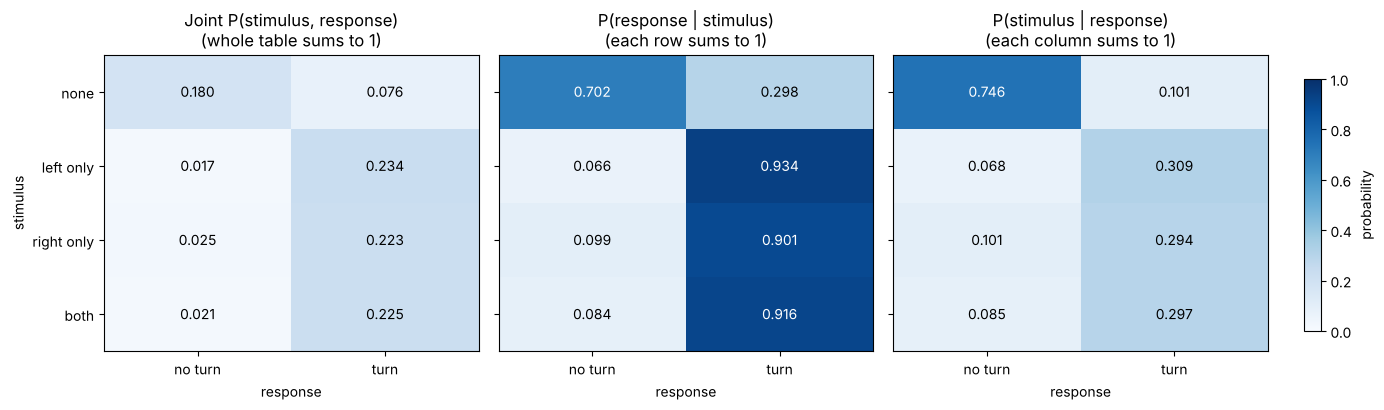

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
panels = [(P_sim, 'Joint P(stimulus, response)\n(whole table sums to 1)'),
          (condition_on_rows(N_sim), 'P(response | stimulus)\n(each row sums to 1)'),
          (N_sim / N_sim.sum(axis=0, keepdims=True), 'P(stimulus | response)\n(each column sums to 1)')]
for ax, (M, title) in zip(axes, panels):
    im = ax.imshow(M, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f'{M[i, j]:.3f}', ha='center', va='center', color='white' if M[i, j] > 0.55 else 'black', fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['no turn', 'turn']); ax.set_yticks(range(4))
    ax.set_yticklabels(stim_levels if ax is axes[0] else [])
    ax.set_xlabel('response'); ax.set_title(title)
axes[0].set_ylabel('stimulus')
plt.tight_layout(rect=[0, 0, 0.92, 1])
fig.colorbar(im, cax=fig.add_axes([0.935, 0.2, 0.012, 0.6]), label='probability')
plt.show()

The three panels hold the same counts divided in three different ways. The middle panel answers "**given** this stimulus, how likely is a turn?" (about 0.3 for blank trials, 0.9 otherwise, as designed). The right panel answers the reverse question, "**given** a turn, which stimulus was it?": only about 10% of turns follow blank trials, because blank trials are rare **and** produce few turns. $P(\text{turn} \mid \text{none}) \approx 0.30$ while $P(\text{none} \mid \text{turn}) \approx 0.10$: same numerator, different denominators. Lesson 19 turns this reversal into Bayes' rule.

Every estimated probability here differs a little from the design values (0.25 for each stimulus, 0.3 and 0.9 for turning): sampling noise again.

# **Part 4: Independence, Dependence and the Law of Total Probability**

### Independence
Events $A$ and $B$ are **independent** if

$$P(A \cap B) = P(A)\,P(B),$$

equivalently (when $P(B) > 0$) $P(A \mid B) = P(A)$: learning that $B$ happened does not change the probability of $A$. Otherwise they are **dependent**. Two variables are independent if every pair of their events is; for a joint table this means $p_{ij} = P(X = x_i)\,P(Y = y_j)$ for **every** cell, i.e. every row of $P(Y \mid X)$ is the same.

- **Independent is not the same as disjoint.** Disjoint events with positive probability are strongly dependent: if one happens, the other cannot.
- **Independence is a property of probabilities, not of mechanisms.** Two neurons with no synaptic connection can still be dependent, if both are driven by the same stimulus.
- **Conditional independence:** $A$ and $B$ are independent given $C$ if $P(A \cap B \mid C) = P(A \mid C)\,P(B \mid C)$. Variables can be independent given $C$ and yet dependent overall, and the reverse.

### The law of total probability
If $B_1, \dots, B_m$ **partition** $\Omega$ (disjoint, and together covering every outcome), then $A = \bigcup_i (A \cap B_i)$ with disjoint pieces, so additivity and the product rule give

$$P(A) = \sum_{i=1}^{m} P(A \mid B_i)\,P(B_i).$$

An overall probability is a **weighted average** of conditional probabilities, weighted by how common each condition is.

In [9]:
# Two neurons that never interact, both driven by the same stimulus. Each spikes in the response window with a probability
# that depends only on whether the stimulus is present; given the stimulus, their spikes are drawn independently.
n_pair = 20000
S_on = RNG.random(n_pair) < 0.5                                             # (20000,) stimulus present on half the trials
pA_given = np.where(S_on, 0.6, 0.1)                                         # (20000,) P(neuron A spikes | stimulus state)
pB_given = np.where(S_on, 0.5, 0.2)                                         # (20000,) P(neuron B spikes | stimulus state)
A_sp = RNG.random(n_pair) < pA_given                                        # (20000,) events, drawn independently given S
B_sp = RNG.random(n_pair) < pB_given

print("marginally (all trials pooled):")
print(f"  P(A and B) = {prob(A_sp & B_sp):.4f}   P(A) P(B) = {prob(A_sp) * prob(B_sp):.4f}   "
      f"P(A | B) = {prob(A_sp & B_sp) / prob(B_sp):.3f} vs P(A) = {prob(A_sp):.3f}   -> dependent")
print("  exact values: P(A and B) = 0.5*0.6*0.5 + 0.5*0.1*0.2 = 0.160;  P(A) P(B) = 0.35*0.35 = 0.1225")
for lab, m in [('stimulus present', S_on), ('stimulus absent', ~S_on)]:
    pa, pb, pab = A_sp[m].mean(), B_sp[m].mean(), (A_sp & B_sp)[m].mean()
    print(f"given {lab:<17}: P(A and B | .) = {pab:.4f}   P(A | .) P(B | .) = {pa * pb:.4f}   -> independent given the stimulus (up to sampling noise)")
print(f"law of total probability: P(A) = P(A|S)P(S) + P(A|not S)P(not S) = {A_sp[S_on].mean() * prob(S_on) + A_sp[~S_on].mean() * prob(~S_on):.4f};  "
      f"direct P(A) = {prob(A_sp):.4f}")

marginally (all trials pooled):
  P(A and B) = 0.1553   P(A) P(B) = 0.1190   P(A | B) = 0.450 vs P(A) = 0.345   -> dependent
  exact values: P(A and B) = 0.5*0.6*0.5 + 0.5*0.1*0.2 = 0.160;  P(A) P(B) = 0.35*0.35 = 0.1225
given stimulus present : P(A and B | .) = 0.2929   P(A | .) P(B | .) = 0.2972   -> independent given the stimulus (up to sampling noise)
given stimulus absent  : P(A and B | .) = 0.0199   P(A | .) P(B | .) = 0.0192   -> independent given the stimulus (up to sampling noise)
law of total probability: P(A) = P(A|S)P(S) + P(A|not S)P(not S) = 0.3448;  direct P(A) = 0.3448


The two neurons co-fire more often than independence predicts (exactly $0.160$ against $0.1225$; the simulation estimates $0.155$ and $0.119$), yet by construction they never influence each other: the dependence is entirely due to the shared stimulus. Within each stimulus condition the co-firing matches the product. This is the probabilistic form of **confounding**, and it is why "correlated" spike trains need not be connected (Lesson 20 returns to correlation and confounding).

### How large is "zero" in data?
Even for truly independent events, the estimated difference $\hat P(A \cap B) - \hat P(A)\hat P(B)$ is never exactly zero. Before calling a difference real, compare it with the spread you get when independence holds by construction:

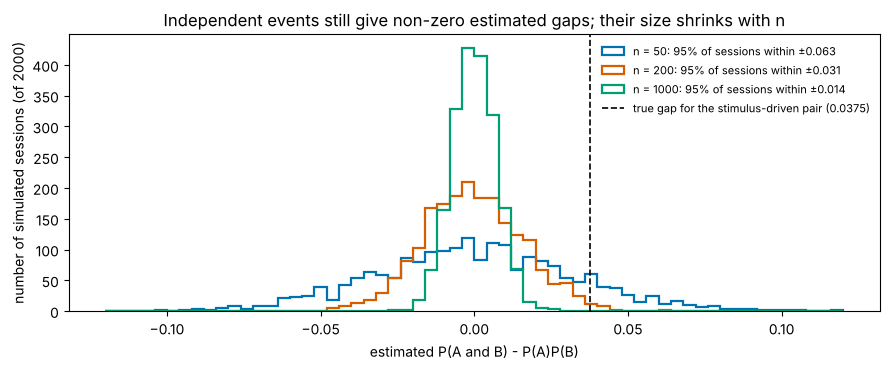

In [10]:
def dependence_gap(n, pa, pb, n_rep=2000):
    # Estimated P(A and B) - P(A)P(B) in n_rep simulated sessions of n trials, with A and B truly independent.
    a = RNG.random((n_rep, n)) < pa
    b = RNG.random((n_rep, n)) < pb
    return (a & b).mean(axis=1) - a.mean(axis=1) * b.mean(axis=1)            # (n_rep,)

fig, ax = plt.subplots(figsize=(9, 3.8))
for n, c in zip([50, 200, 1000], PALETTE):
    gaps = dependence_gap(n, 0.35, 0.35)
    ax.hist(gaps, bins=np.linspace(-0.12, 0.12, 61), histtype='step', color=c, lw=1.6, label=f'n = {n}: 95% of sessions within ±{np.percentile(np.abs(gaps), 95):.3f}')
ax.axvline(0.160 - 0.1225, color='black', ls='--', lw=1.2, label='true gap for the stimulus-driven pair (0.0375)')
ax.set_xlabel('estimated P(A and B) - P(A)P(B)'); ax.set_ylabel('number of simulated sessions (of 2000)')
ax.set_title('Independent events still give non-zero estimated gaps; their size shrinks with n')
ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

With 50 trials, a gap of $\pm0.06$ arises from independent events by chance alone, larger than the real dependence of the stimulus-driven pair. With 1,000 trials the real gap stands well clear of the chance spread. Formal tests and confidence intervals for such comparisons come in Lesson 20; the habit to build now is to **ask how big a difference chance alone produces at your sample size**.

#### Interactive version: shared drive and dependence
The slider changes how strongly the stimulus drives both neurons. With $P(A \mid S) = P(B \mid S) = 0.2 + d$ and $P(A \mid S^{c}) = P(B \mid S^{c}) = 0.2$, the bars show the exact $P(A \cap B)$ and $P(A)P(B)$, pooled and within each stimulus condition.

In [11]:
drives = np.round(np.linspace(0, 0.7, 15), 2)
def pair_probs(d):
    pS = 0.5; a1 = b1 = 0.2 + d; a0 = b0 = 0.2
    pA = a1 * pS + a0 * (1 - pS); pB = b1 * pS + b0 * (1 - pS)
    pAB = a1 * b1 * pS + a0 * b0 * (1 - pS)                                 # law of total probability with conditional independence
    return [pAB, pA * pB, a1 * b1, a1 * b1, a0 * b0, a0 * b0]
cats = ['pooled: P(A and B)', 'pooled: P(A)P(B)', 'S present: P(A and B | S)', 'S present: P(A|S)P(B|S)', 'S absent: P(A and B | not S)', 'S absent: P(A|not S)P(B|not S)']
cols = [PALETTE[1], PALETTE[0]] * 3
fig_d = go.Figure([go.Bar(x=cats, y=np.round(pair_probs(drives[0]), 4), marker_color=cols)])
frames = [go.Frame(name=str(k), data=[go.Bar(y=np.round(pair_probs(d), 4))],
                   layout=go.Layout(title=f'drive d = {d}: pooled gap P(A and B) - P(A)P(B) = {pair_probs(d)[0] - pair_probs(d)[1]:.4f};  gap within each condition = 0'))
          for k, d in enumerate(drives)]
fig_d.frames = frames
buttons, sliders = play_pause_and_slider(list(drives), prefix='drive d = ', duration=400)
fig_d.update_layout(title=frames[0].layout.title.text, yaxis=dict(title='probability', range=[0, 0.85]), template='plotly_white',
                    width=900, height=520, updatemenus=buttons, sliders=sliders, margin=dict(b=170))
fig_d.show(config=PLOTLY_CONFIG)

### When averaging reverses a comparison
Because overall rates are weighted averages, they depend on the **mix** of conditions as well as on the rate within each condition. Two detectors, tested in two different sessions, are each scored by their hit rate on gratings of low and high contrast:

In [12]:
# rows: low contrast, high contrast;  columns: hits, trials
det_A = np.array([[40, 80], [19, 20]])
det_B = np.array([[8, 20], [72, 80]])
for name, t in [('detector A', det_A), ('detector B', det_B)]:
    within = t[:, 0] / t[:, 1]
    mix = t[:, 1] / t[:, 1].sum()                                           # P(contrast) in that detector's test session
    overall = t[:, 0].sum() / t[:, 1].sum()
    print(f"{name}: hit rate low {within[0]:.2f}, high {within[1]:.2f};  mix of trials (low, high) = {np.round(mix, 2)};  "
          f"overall {overall:.2f} = {within[0]:.2f}*{mix[0]:.2f} + {within[1]:.2f}*{mix[1]:.2f}")
common_mix = np.array([0.5, 0.5])
for name, t in [('detector A', det_A), ('detector B', det_B)]:
    print(f"{name} on a common 50/50 mix: {np.sum(t[:, 0] / t[:, 1] * common_mix):.3f}")

detector A: hit rate low 0.50, high 0.95;  mix of trials (low, high) = [0.8 0.2];  overall 0.59 = 0.50*0.80 + 0.95*0.20
detector B: hit rate low 0.40, high 0.90;  mix of trials (low, high) = [0.2 0.8];  overall 0.80 = 0.40*0.20 + 0.90*0.80
detector A on a common 50/50 mix: 0.725
detector B on a common 50/50 mix: 0.650


Detector A is better at **both** contrasts (0.50 against 0.40, and 0.95 against 0.90), yet B has the higher overall hit rate (0.80 against 0.59), because B was mostly tested on easy high-contrast trials. This reversal is **Simpson's paradox**, and the law of total probability explains it completely: each overall rate is a weighted average with different weights. Compared on the **same** mix of conditions, A wins. Whenever two groups differ in the mix of conditions (contrast, difficulty, cell type, patient age), compare within conditions or standardise to a common mix.

# **Part 5: Detection and the Confusion Matrix**

A **binary detector** (a neuron, a mouse, a classifier, a diagnostic test) says "yes" or "no" on each trial, and the truth is "signal present" or "absent". Crossing the two gives four outcomes, counted in the **confusion matrix**. In this course, **rows are the truth and columns are the decision**:

| | decision: yes | decision: no |
|---|---|---|
| **truth: present** | hit (true positive, TP) | miss (false negative, FN) |
| **truth: absent** | false alarm (false positive, FP) | correct rejection (true negative, TN) |

(Software differs: scikit-learn's `confusion_matrix` orders classes as `[negative, positive]`, so its first row is "absent". Always check the layout before reading a confusion matrix.)

Every summary rate is a **conditional probability**, and the denominator says which:

| Name(s) | Definition | Conditional probability |
|---|---|---|
| hit rate, sensitivity, recall, true-positive rate | TP / (TP + FN) | $P(\text{yes} \mid \text{present})$ |
| miss rate | FN / (TP + FN) = 1 − hit rate | $P(\text{no} \mid \text{present})$ |
| false-alarm rate, false-positive rate | FP / (FP + TN) | $P(\text{yes} \mid \text{absent})$ |
| specificity, true-negative rate | TN / (FP + TN) = 1 − false-alarm rate | $P(\text{no} \mid \text{absent})$ |
| precision, positive predictive value | TP / (TP + FP) | $P(\text{present} \mid \text{yes})$ |
| accuracy | (TP + TN) / n | $P(\text{decision correct})$ |

Sensitivity and specificity condition on the **truth**, so they do not depend on how common the signal is. Precision conditions on the **decision**, and accuracy averages over both classes, so both depend on the **base rate** (prevalence) $\pi = P(\text{present})$. By the law of total probability,

$$\text{accuracy} = \text{sensitivity}\cdot\pi + \text{specificity}\cdot(1 - \pi),\qquad
\text{precision} = \frac{\text{sensitivity}\cdot\pi}{\text{sensitivity}\cdot\pi + (1 - \text{specificity})(1 - \pi)}.$$

The precision formula is just $P(\text{present} \cap \text{yes})/P(\text{yes})$, with both pieces computed by the product rule and the law of total probability.

In [13]:
def confusion(truth, decision):
    # 2 x 2 counts. Rows: truth (present, absent); columns: decision (yes, no).
    truth, decision = np.asarray(truth), np.asarray(decision)
    if truth.dtype != bool or decision.dtype != bool or truth.shape != decision.shape or truth.ndim != 1:
        raise ValueError("truth and decision must be aligned 1-D Boolean arrays")
    return np.array([[np.sum(truth & decision), np.sum(truth & ~decision)],
                     [np.sum(~truth & decision), np.sum(~truth & ~decision)]])

def detection_rates(cm):
    # Summary rates from a confusion matrix in the course layout. Undefined rates (zero denominators) are NaN.
    (tp, fn), (fp, tn) = np.asarray(cm, dtype=float)
    div = lambda a, b: float(a / b) if b > 0 else float('nan')
    return {'hit rate (sensitivity)': div(tp, tp + fn), 'false-alarm rate': div(fp, fp + tn), 'specificity': div(tn, fp + tn),
            'precision': div(tp, tp + fp), 'accuracy': div(tp + tn, tp + fn + fp + tn), 'base rate': div(tp + fn, tp + fn + fp + tn)}

# The simulated mouse of Part 1 as a grating detector: truth = any grating, decision = turned the wheel.
cm_sim = confusion(L_ev | R_ev, go_sim)
print("confusion matrix (rows: present, absent; columns: yes, no):\n", cm_sim)
for k, v in detection_rates(cm_sim).items():
    print(f"  {k:<24}{v:.3f}")
print("check: accuracy = sens*pi + spec*(1 - pi):",
      np.isclose(detection_rates(cm_sim)['accuracy'], detection_rates(cm_sim)['hit rate (sensitivity)'] * detection_rates(cm_sim)['base rate']
                 + detection_rates(cm_sim)['specificity'] * (1 - detection_rates(cm_sim)['base rate'])))
always_yes = confusion(L_ev | R_ev, np.ones(n_sim, dtype=bool))
print("a detector that always says yes:", {k: round(v, 3) for k, v in detection_rates(always_yes).items()})

confusion matrix (rows: present, absent; columns: yes, no):
 [[1363  123]
 [ 153  361]]
  hit rate (sensitivity)  0.917
  false-alarm rate        0.298
  specificity             0.702
  precision               0.899
  accuracy                0.862
  base rate               0.743
check: accuracy = sens*pi + spec*(1 - pi): True
a detector that always says yes: {'hit rate (sensitivity)': 1.0, 'false-alarm rate': 1.0, 'specificity': 0.0, 'precision': 0.743, 'accuracy': 0.743, 'base rate': 0.743}


The "always yes" detector has a perfect hit rate and accuracy equal to the base rate (0.74 here), which looks respectable, but its false-alarm rate is 1 and its specificity 0. **Report sensitivity and specificity (or hit and false-alarm rates) together**, never one alone, and never accuracy alone when the classes are unbalanced.

### The base rate and precision
Take a detector with sensitivity 0.9 and specificity 0.9 (for example, a spike-sorting step deciding whether a waveform is a real spike, or a seizure detector scanning one-second windows). Its precision depends on how common the signal is:

 base rate  P(present and yes)    P(yes)  precision  accuracy  accuracy of always-no
      0.50              0.4500    0.5000      0.900     0.900                  0.500
      0.20              0.1800    0.2600      0.692     0.900                  0.800
      0.05              0.0450    0.1400      0.321     0.900                  0.950
      0.01              0.0090    0.1080      0.083     0.900                  0.990


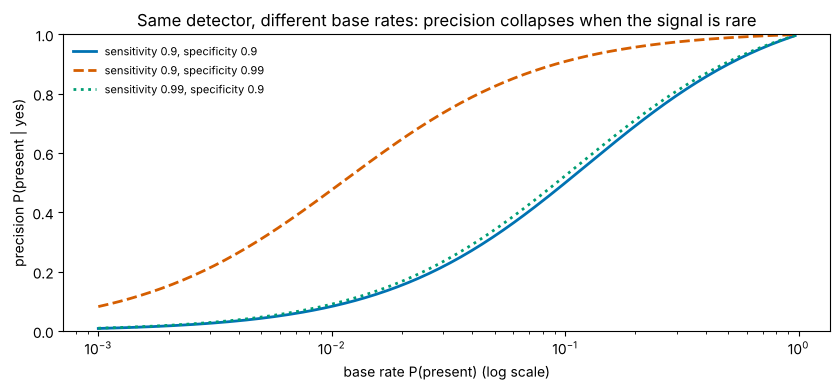

In [14]:
sens, spec = 0.9, 0.9
base_rates = np.array([0.5, 0.2, 0.05, 0.01])
print(f"{'base rate':>10}{'P(present and yes)':>20}{'P(yes)':>10}{'precision':>11}{'accuracy':>10}{'accuracy of always-no':>23}")
for pi in base_rates:
    p_tp = sens * pi                                                        # product rule
    p_yes = sens * pi + (1 - spec) * (1 - pi)                               # law of total probability
    print(f"{pi:>10.2f}{p_tp:>20.4f}{p_yes:>10.4f}{p_tp / p_yes:>11.3f}{sens * pi + spec * (1 - pi):>10.3f}{1 - pi:>23.3f}")

pi_grid = np.logspace(-3, 0, 200)[:-1]
fig, ax = plt.subplots(figsize=(8.5, 4))
for (se, sp), c, ls in zip([(0.9, 0.9), (0.9, 0.99), (0.99, 0.9)], PALETTE, LINESTYLES):
    ax.semilogx(pi_grid, se * pi_grid / (se * pi_grid + (1 - sp) * (1 - pi_grid)), ls, color=c, lw=2, label=f'sensitivity {se}, specificity {sp}')
ax.set_xlabel('base rate P(present) (log scale)'); ax.set_ylabel('precision P(present | yes)')
ax.set_title('Same detector, different base rates: precision collapses when the signal is rare')
ax.set_ylim(0, 1); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

At a base rate of 1%, nine out of ten "yes" decisions of this good-looking detector are false alarms (precision about 0.08), while its accuracy is 0.9; the useless "always no" rule scores 0.99. The curves show what helps: when the signal is rare, raising **specificity** (dashed) improves precision far more than raising sensitivity (dotted). This matters wherever the event of interest is rare: spikes among noise windows, seizures among EEG seconds, active voxels among a whole brain.

# **Part 6: Thresholds and Trade-offs**

Most detectors compute a **score** on each trial (a spike count, a classifier output) and decide "yes" when the score reaches a **threshold** $t$:

$$\text{decision} = \text{yes} \iff \text{score} \ge t .$$

Raising $t$ makes "yes" rarer, so the hit rate **and** the false-alarm rate both fall (neither can rise); lowering it raises both. No threshold improves one without worsening the other, unless the score separates the classes perfectly. Plotting the hit rate against the false-alarm rate as $t$ moves traces the **receiver operating characteristic (ROC) curve**; Lesson 20 analyses it, together with the area under it (AUC).

Which threshold is "best" depends on what errors cost and on the base rate. One simple criterion: minimise the **weighted number of errors**, $c_{\text{miss}}\cdot\text{FN} + c_{\text{FA}}\cdot\text{FP}$. Two rules of good practice:
- **choose the threshold on training trials and report its rates on separate test trials**: a threshold tuned and scored on the same trials gives optimistic rates;
- **state the tie rule** (`>=` or `>`): with integer counts many trials sit exactly on the threshold.

Below, a simulated neuron fires more spikes in a 200 ms window when a stimulus is present. (The counts are drawn from a Poisson model, the subject of Lesson 18; here they are simply data.)

In [15]:
n_det = 1000
present = RNG.random(n_det) < 0.3                                          # (1000,) truth: stimulus on 30% of trials
counts = RNG.poisson(np.where(present, 8.0, 3.0))                          # (1000,) spikes in a 200 ms window
train = np.arange(n_det) < n_det // 2; test = ~train                        # first half to choose, second half to report
thresholds = np.arange(0, counts.max() + 2)                                 # integer thresholds; decision: count >= t

def rates_at(t, rows):
    cm = confusion(present[rows], counts[rows] >= t)
    r = detection_rates(cm)
    return r['hit rate (sensitivity)'], r['false-alarm rate'], cm

H_tr = np.array([rates_at(t, train)[0] for t in thresholds]); F_tr = np.array([rates_at(t, train)[1] for t in thresholds])
print(f"{'t':>3}{'hit rate':>10}{'FA rate':>9}{'misses':>8}{'FAs':>6}{'errors':>8}{'misses x5 + FAs':>17}   (training half)")
for t in range(0, 12):
    h, f, cm = rates_at(t, train)
    print(f"{t:>3}{h:>10.3f}{f:>9.3f}{cm[0, 1]:>8}{cm[1, 0]:>6}{cm[0, 1] + cm[1, 0]:>8}{5 * cm[0, 1] + cm[1, 0]:>17}")
assert np.all(np.diff(H_tr) <= 0) and np.all(np.diff(F_tr) <= 0), "both rates must fall as the threshold rises"

def best_threshold(rows, c_miss=1.0, c_fa=1.0):
    costs = [c_miss * rates_at(t, rows)[2][0, 1] + c_fa * rates_at(t, rows)[2][1, 0] for t in thresholds]
    return int(thresholds[int(np.argmin(costs))])
t_equal, t_miss5 = best_threshold(train), best_threshold(train, c_miss=5)
for lab, t in [('equal costs', t_equal), ('a miss costs 5 false alarms', t_miss5)]:
    h_tr, f_tr, _ = rates_at(t, train); h_te, f_te, cm_te = rates_at(t, test)
    print(f"{lab:<28}: t = {t};  training hit/FA = {h_tr:.3f}/{f_tr:.3f};  TEST hit/FA = {h_te:.3f}/{f_te:.3f};  test errors {cm_te[0, 1] + cm_te[1, 0]} of {test.sum()}")

  t  hit rate  FA rate  misses   FAs  errors  misses x5 + FAs   (training half)
  0     1.000    1.000       0   353     353              353
  1     1.000    0.958       0   338     338              338
  2     0.993    0.805       1   284     285              289
  3     0.980    0.623       3   220     223              235
  4     0.959    0.411       6   145     151              175
  5     0.878    0.212      18    75      93              165
  6     0.782    0.074      32    26      58              186
  7     0.694    0.028      45    10      55              235
  8     0.592    0.014      60     5      65              305
  9     0.503    0.008      73     3      76              368
 10     0.333    0.000      98     0      98              490
 11     0.238    0.000     112     0     112              560
equal costs                 : t = 7;  training hit/FA = 0.694/0.028;  TEST hit/FA = 0.678/0.037;  test errors 60 of 500
a miss costs 5 false alarms : t = 5;  training hit/FA = 

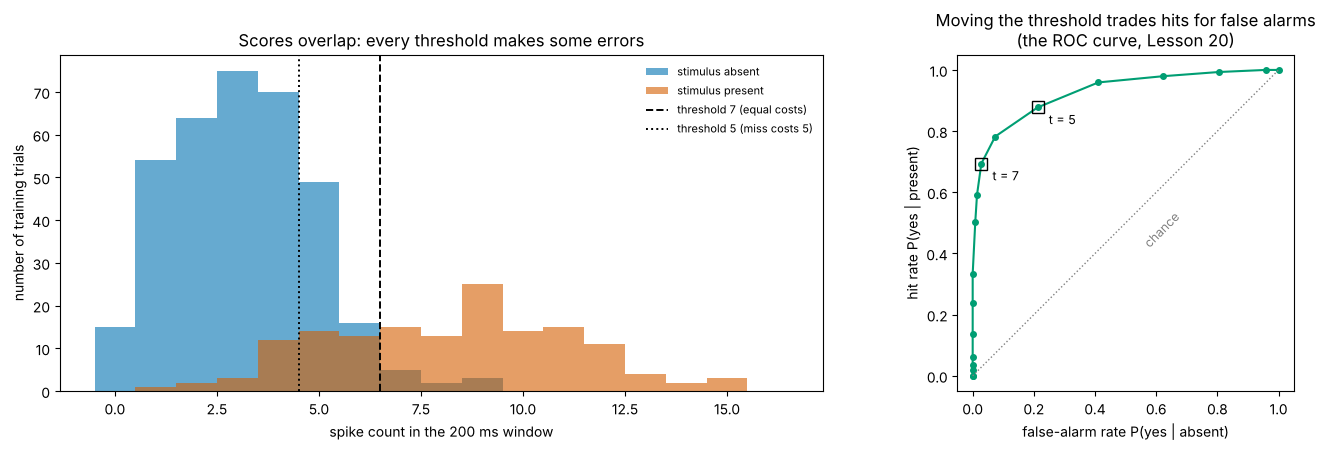

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.5, 1]})
bins = np.arange(-0.5, counts.max() + 1.5)
axes[0].hist(counts[train & ~present], bins=bins, color=PALETTE[0], alpha=0.6, label='stimulus absent')
axes[0].hist(counts[train & present], bins=bins, color=PALETTE[1], alpha=0.6, label='stimulus present')
for t, ls, lab in [(t_equal, '--', f'threshold {t_equal} (equal costs)'), (t_miss5, ':', f'threshold {t_miss5} (miss costs 5)')]:
    axes[0].axvline(t - 0.5, color='black', ls=ls, lw=1.4, label=lab)
axes[0].set_xlabel('spike count in the 200 ms window'); axes[0].set_ylabel('number of training trials')
axes[0].set_title('Scores overlap: every threshold makes some errors'); axes[0].legend(fontsize=8, frameon=False)
axes[1].plot(F_tr, H_tr, '-', color=PALETTE[2], lw=1.5, marker='o', ms=4)
for t in [t_equal, t_miss5]:
    axes[1].plot(F_tr[t], H_tr[t], 's', color='black', ms=8, mfc='none')
    axes[1].annotate(f't = {t}', (F_tr[t], H_tr[t]), xytext=(8, -12), textcoords='offset points', fontsize=9)
axes[1].plot([0, 1], [0, 1], ':', color='grey', lw=1); axes[1].text(0.55, 0.42, 'chance', color='grey', fontsize=9, rotation=45)
axes[1].set_xlabel('false-alarm rate P(yes | absent)'); axes[1].set_ylabel('hit rate P(yes | present)')
axes[1].set_title('Moving the threshold trades hits for false alarms\n(the ROC curve, Lesson 20)'); axes[1].set_aspect('equal')
plt.tight_layout(); plt.show()

Every point on the right-hand curve is one threshold. Moving down the curve (raising $t$) gives up hits to remove false alarms. With equal costs the error-minimising threshold sits where the two histograms cross; when a miss costs five false alarms, the best threshold moves lower and accepts more false alarms. The test-half rates differ somewhat from the training-half rates: they are the honest estimates.

#### Interactive version: move the threshold

In [17]:
ths_i = list(range(0, 15))
def thr_frame(t):
    h, f, cm = rates_at(t, train)
    return h, f, cm
h0, f0, cm0 = thr_frame(ths_i[0])
fig_t = go.Figure([
    go.Scatter(x=np.round(F_tr, 4), y=np.round(H_tr, 4), mode='lines+markers', marker=dict(size=5, color=PALETTE[2]), line=dict(color=PALETTE[2]), name='all thresholds'),
    go.Scatter(x=[round(f0, 4)], y=[round(h0, 4)], mode='markers', marker=dict(size=16, color=PALETTE[1], symbol='square'), name='current threshold'),
    go.Scatter(x=[0, 1], y=[0, 1], mode='lines', line=dict(color='grey', dash='dot'), name='chance')])
frs = []
for k, t in enumerate(ths_i):
    h, f, cm = thr_frame(t)
    frs.append(go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=[round(f, 4)], y=[round(h, 4)])],
                        layout=go.Layout(title=f'yes if count >= {t}:  hits {cm[0, 0]}, misses {cm[0, 1]}, false alarms {cm[1, 0]}, correct rejections {cm[1, 1]}  (hit {h:.2f}, FA {f:.2f})')))
fig_t.frames = frs
buttons, sliders = play_pause_and_slider(ths_i, prefix='threshold t = ', duration=500)
fig_t.update_layout(title=frs[0].layout.title.text, xaxis=dict(title='false-alarm rate', range=[-0.02, 1.02]), yaxis=dict(title='hit rate', range=[-0.02, 1.02], scaleanchor='x'),
                    template='plotly_white', width=760, height=640, updatemenus=buttons, sliders=sliders)
fig_t.show(config=PLOTLY_CONFIG)

# **Part 7: Mini-Lab — What the Mouse Saw, What It Did, and What V1 Knew**

**Data.** One session (mouse Lederberg, 5 December 2017) from [Steinmetz et al. (2019)](https://doi.org/10.1038/s41586-019-1787-x), in the trial-binned form released by Neuromatch Academy. On each of 340 trials, gratings of contrast 0, 0.25, 0.5 or 1 appeared on the left and right; the mouse turned a wheel to bring the higher-contrast grating to the centre, or held the wheel still if there was no grating. The file is a small subset stored in the course repository (`data/steinmetz_s11_lederberg.npz`):

| Array | Shape | Meaning, units |
|---|---|---|
| `counts` | (340, 698) | spikes of each neuron in the window 50–250 ms after stimulus onset (rows: trials; columns: neurons) |
| `brain_area` | (698,) | brain area of each neuron (Allen atlas acronym) |
| `contrast_left`, `contrast_right` | (340,) | contrast of each grating, 0 to 1 (0 = no grating) |
| `response` | (340,) | wheel turn: +1 left, −1 right, 0 none |

All neurons were recorded in the **left** hemisphere, so a **right** grating is in the visual field that the recorded primary visual cortex (VISp) represents.

**Plan.**
1. Events from the stimulus design: are "left grating" and "right grating" independent?
2. The joint table of stimulus and response; conditional probabilities in both directions.
3. The mouse as a detector: hit and false-alarm rates; the law of total probability.
4. VISp as a detector of right gratings: threshold chosen on half the trials, rates reported on the other half; sensitivity by contrast.
5. Does VISp respond to **left** gratings? Marginal against conditional probabilities.

In [18]:
import os, urllib.request

DATA_FILE = 'steinmetz_s11_lederberg.npz'
for candidate in [DATA_FILE, os.path.join('..', '..', 'data', DATA_FILE)]:          # local copy, or the repository's data folder
    if os.path.exists(candidate):
        DATA_PATH = candidate; break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/8f9e0431a21d8ac0aa016e3502735f3b8627863a/data/' + DATA_FILE, DATA_FILE)
    DATA_PATH = DATA_FILE
dat = np.load(DATA_PATH)
spk = dat['counts'].astype(float)                                          # (340, 698) spikes in 0.2 s
area = dat['brain_area']                                                   # (698,)
cl, cr, resp = dat['contrast_left'], dat['contrast_right'], dat['response']  # (340,) each
n_tr = len(resp)
print("counts", spk.shape, "  brain_area", area.shape, "  contrasts", cl.shape, cr.shape, "  response", resp.shape)
print("window:", float(dat['window_start_s']), "to", float(dat['window_start_s'] + dat['window_s']), "s after stimulus onset")
print("neurons per area:", {str(a): int(np.sum(area == a)) for a in np.unique(area)})

Lg, Rg = cl > 0, cr > 0                                                     # events: grating on the left / right
print(f"\nP(L) = {prob(Lg):.3f}  P(R) = {prob(Rg):.3f}  P(L and R) = {prob(Lg & Rg):.3f}  P(L)P(R) = {prob(Lg) * prob(Rg):.3f}")
print(f"P(R | L) = {prob(Lg & Rg) / prob(Lg):.3f}   P(R | not L) = {prob(~Lg & Rg) / prob(~Lg):.3f}")
print(f"inclusion-exclusion: P(L or R) = {prob(Lg | Rg):.3f} = {prob(Lg) + prob(Rg) - prob(Lg & Rg):.3f}")
gap_null = dependence_gap(n_tr, prob(Lg), prob(Rg))
print(f"observed gap P(L and R) - P(L)P(R) = {prob(Lg & Rg) - prob(Lg) * prob(Rg):+.3f};  95% of independent simulated sessions of {n_tr} trials lie within ±{np.percentile(np.abs(gap_null), 95):.3f}")

counts (340, 698)   brain_area (698,)   contrasts (340,) (340,)   response (340,)
window: 0.05 to 0.25 s after stimulus onset
neurons per area: {'ACA': 16, 'CA1': 50, 'DG': 65, 'LGd': 11, 'LH': 18, 'MD': 126, 'MOs': 6, 'PL': 56, 'SUB': 105, 'VISam': 79, 'VISp': 66, 'root': 100}

P(L) = 0.491  P(R) = 0.509  P(L and R) = 0.318  P(L)P(R) = 0.250
P(R | L) = 0.647   P(R | not L) = 0.376
inclusion-exclusion: P(L or R) = 0.682 = 0.682
observed gap P(L and R) - P(L)P(R) = +0.068;  95% of independent simulated sessions of 340 trials lie within ±0.026


The two gratings are **not** independent in this session's design: a right grating appeared on about 65% of trials that had a left grating but only about 38% of those without one, a gap far outside what independent events produce in 340 trials. (The task's trial schedule ties the two sides together; whatever the reason, it is a property of these trials that we must account for in step 5.)

### The joint table of stimulus and response

joint counts (rows: stimulus; columns: turn left, no turn, turn right):
 [[18 50 40]
 [97  1  5]
 [ 9 13 89]
 [11  0  7]]
marginal P(stimulus): {'none': 0.318, 'left higher': 0.303, 'right higher': 0.326, 'equal': 0.053}
marginal P(response): {'turn left': 0.397, 'no turn': 0.188, 'turn right': 0.415}


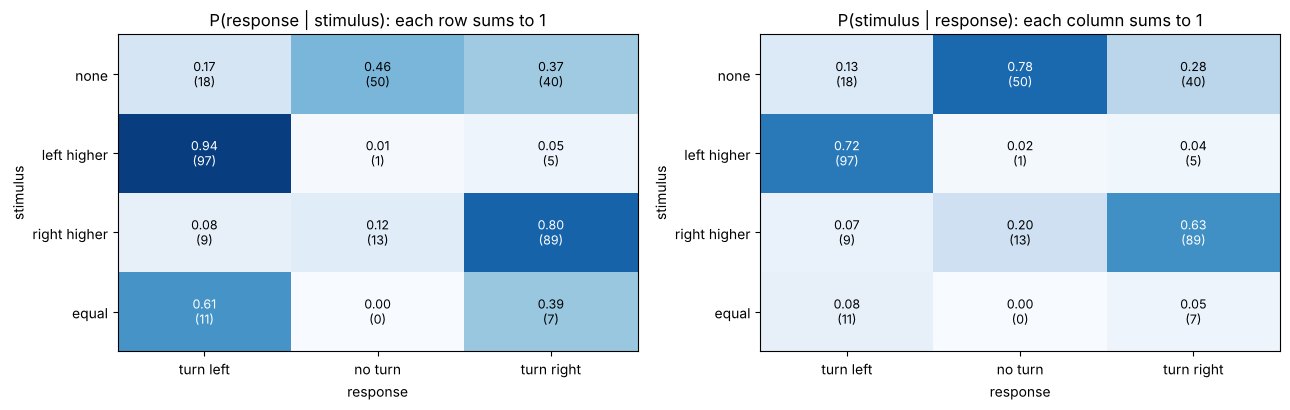

P(turn right | no grating) = 0.370   but   P(no grating | turn right) = 0.284


In [19]:
stim_cond = np.select([~Lg & ~Rg, cl > cr, cr > cl], ['none', 'left higher', 'right higher'], default='equal')   # (340,) labels
stim_lv = ['none', 'left higher', 'right higher', 'equal']
resp_lv = [1, 0, -1]                                                       # turn left, no turn, turn right
resp_names = ['turn left', 'no turn', 'turn right']
N_m = joint_counts(stim_cond, resp, stim_lv, resp_lv)                      # (4, 3) counts
P_m = N_m / N_m.sum()
print("joint counts (rows: stimulus; columns: turn left, no turn, turn right):\n", N_m)
print("marginal P(stimulus):", dict(zip(stim_lv, np.round(P_m.sum(axis=1), 3).tolist())))
print("marginal P(response):", dict(zip(resp_names, np.round(P_m.sum(axis=0), 3).tolist())))
cond_rs = condition_on_rows(N_m)
cond_sr = N_m / N_m.sum(axis=0, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, M, title in [(axes[0], cond_rs, 'P(response | stimulus): each row sums to 1'), (axes[1], cond_sr, 'P(stimulus | response): each column sums to 1')]:
    ax.imshow(M, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    for i in range(4):
        for j in range(3):
            ax.text(j, i, f'{M[i, j]:.2f}\n({N_m[i, j]})', ha='center', va='center', fontsize=9, color='white' if M[i, j] > 0.55 else 'black')
    ax.set_xticks(range(3)); ax.set_xticklabels(resp_names); ax.set_yticks(range(4)); ax.set_yticklabels(stim_lv)
    ax.set_xlabel('response'); ax.set_ylabel('stimulus'); ax.set_title(title)
plt.tight_layout(); plt.show()
print(f"P(turn right | no grating) = {cond_rs[0, 2]:.3f}   but   P(no grating | turn right) = {cond_sr[0, 2]:.3f}")

On trials with a clearly higher-contrast side, the mouse turned the correct way on about 94% (left higher) and 80% (right higher) of trials. On blank trials it held still on fewer than half and turned **right** on more than a third: a strong response bias. Reading the table the other way, a right turn came from a blank trial only about 28% of the time. The two conditional probabilities answer different questions; neither can be read off the other without the marginals.

### The mouse as a grating detector
Treat "any grating" as the signal and "any wheel turn" as the decision "yes". (In this task the mouse is rewarded for holding still on blank trials, so a turn on a blank trial is a genuine error.)

In [20]:
present_m, go_m = Lg | Rg, resp != 0
cm_mouse = confusion(present_m, go_m)
r_mouse = detection_rates(cm_mouse)
print("confusion matrix (rows: grating present, absent; columns: turn, no turn):\n", cm_mouse)
print({k: round(v, 3) for k, v in r_mouse.items()})
p_go_total = r_mouse['hit rate (sensitivity)'] * prob(present_m) + r_mouse['false-alarm rate'] * prob(~present_m)
print(f"law of total probability: P(turn) = P(turn|present)P(present) + P(turn|absent)P(absent) = "
      f"{r_mouse['hit rate (sensitivity)']:.3f}*{prob(present_m):.3f} + {r_mouse['false-alarm rate']:.3f}*{prob(~present_m):.3f} = {p_go_total:.3f};  direct {prob(go_m):.3f}")

confusion matrix (rows: grating present, absent; columns: turn, no turn):
 [[218  14]
 [ 58  50]]
{'hit rate (sensitivity)': 0.94, 'false-alarm rate': 0.537, 'specificity': 0.463, 'precision': 0.79, 'accuracy': 0.788, 'base rate': 0.682}
law of total probability: P(turn) = P(turn|present)P(present) + P(turn|absent)P(absent) = 0.940*0.682 + 0.537*0.318 = 0.812;  direct 0.812


The mouse's hit rate is 0.94 but its false-alarm rate is 0.54: it turns the wheel on more than half of the blank trials. Its accuracy (about 0.79) mostly reflects how common grating trials are. A behavioural "detection" summary that reports only the hit rate would be badly misleading, which is exactly the motivating question of this lesson.

### VISp as a detector of right gratings
For each trial, add up the spike counts of the 66 VISp neurons: one **score** per trial, shape `(340,)`. The truth is $R$ (right grating present). We choose the threshold on a random half of the trials (`RNG`, seeded) and report rates on the other half.

In [21]:
visp = area == 'VISp'
score = spk[:, visp].sum(axis=1)                                            # (340,) total VISp spikes in 50-250 ms
perm = RNG.permutation(n_tr)
tr_m = np.zeros(n_tr, dtype=bool); tr_m[perm[:n_tr // 2]] = True; te_m = ~tr_m
ths_m = np.arange(0, int(score.max()) + 2)
def cm_at(t, rows):
    return confusion(Rg[rows], score[rows] >= t)
err_tr = np.array([cm_at(t, tr_m)[0, 1] + cm_at(t, tr_m)[1, 0] for t in ths_m])
t_star = int(ths_m[np.argmin(err_tr)])
cm_tr, cm_te = cm_at(t_star, tr_m), cm_at(t_star, te_m)
print(f"VISp neurons: {visp.sum()};  threshold chosen on {tr_m.sum()} training trials: yes if total count >= {t_star} spikes (in 0.2 s)")
print(f"training: {({k: round(v, 3) for k, v in detection_rates(cm_tr).items()})}")
print(f"TEST:     {({k: round(v, 3) for k, v in detection_rates(cm_te).items()})}")
print("test confusion matrix (rows: right grating present, absent; columns: yes, no):\n", cm_te)

yes_m = score >= t_star
hit_by_c = {c: yes_m[te_m & (cr == c)].mean() for c in [0.25, 0.5, 1.0]}
mix_c = {c: np.sum(te_m & (cr == c)) / np.sum(te_m & Rg) for c in [0.25, 0.5, 1.0]}
for c in [0.25, 0.5, 1.0]:
    print(f"  right contrast {c:<4}: test hit rate {hit_by_c[c]:.3f} on {np.sum(te_m & (cr == c))} trials;  P(contrast {c} | right grating) = {mix_c[c]:.3f}")
print(f"law of total probability: sum of hit(c) P(c | present) = {sum(hit_by_c[c] * mix_c[c] for c in hit_by_c):.3f}  "
      f"= overall test hit rate {detection_rates(cm_te)['hit rate (sensitivity)']:.3f}")
print(f"same detector on a session with only 0.25-contrast gratings: expected hit rate {hit_by_c[0.25]:.3f};  only full contrast: {hit_by_c[1.0]:.3f}")

VISp neurons: 66;  threshold chosen on 170 training trials: yes if total count >= 31 spikes (in 0.2 s)


training: {'hit rate (sensitivity)': 0.878, 'false-alarm rate': 0.075, 'specificity': 0.925, 'precision': 0.929, 'accuracy': 0.9, 'base rate': 0.529}
TEST:     {'hit rate (sensitivity)': 0.807, 'false-alarm rate': 0.08, 'specificity': 0.92, 'precision': 0.905, 'accuracy': 0.865, 'base rate': 0.488}
test confusion matrix (rows: right grating present, absent; columns: yes, no):
 [[67 16]
 [ 7 80]]
  right contrast 0.25: test hit rate 0.548 on 31 trials;  P(contrast 0.25 | right grating) = 0.373
  right contrast 0.5 : test hit rate 0.950 on 20 trials;  P(contrast 0.5 | right grating) = 0.241
  right contrast 1.0 : test hit rate 0.969 on 32 trials;  P(contrast 1.0 | right grating) = 0.386
law of total probability: sum of hit(c) P(c | present) = 0.807  = overall test hit rate 0.807
same detector on a session with only 0.25-contrast gratings: expected hit rate 0.548;  only full contrast: 0.969


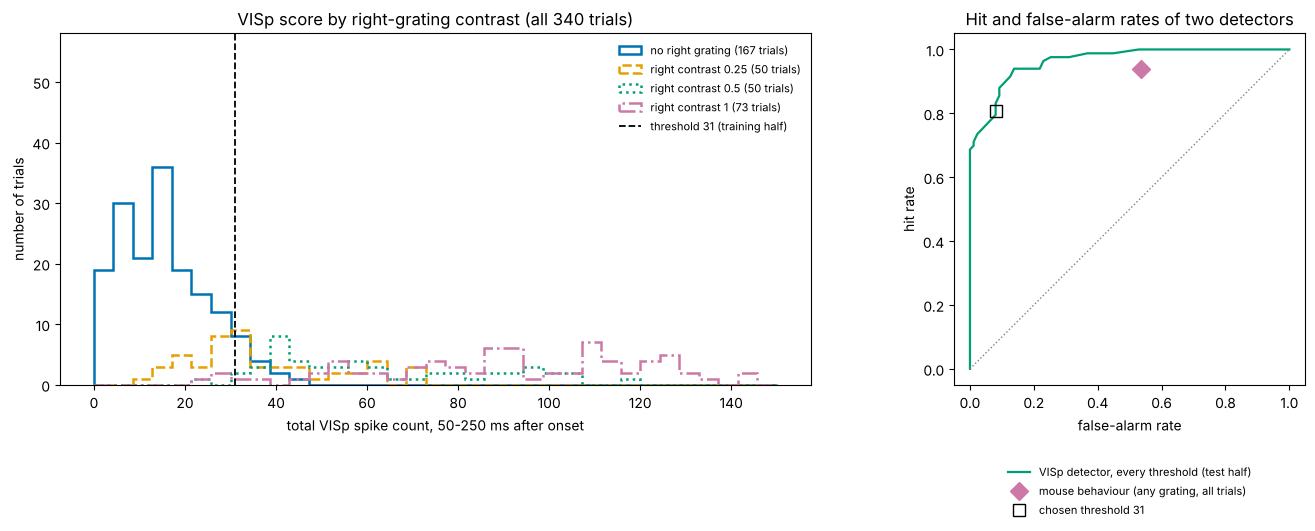

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1.5, 1]})
bins_m = np.linspace(0, score.max() + 5, 36)
for c, col, ls, lab in [(0.0, PALETTE[0], '-', 'no right grating'), (0.25, PALETTE[4], '--', 'right contrast 0.25'), (0.5, PALETTE[2], ':', 'right contrast 0.5'), (1.0, PALETTE[3], '-.', 'right contrast 1')]:
    axes[0].hist(score[cr == c], bins=bins_m, histtype='step', lw=1.8, color=col, ls=ls, label=f'{lab} ({np.sum(cr == c)} trials)')
axes[0].axvline(t_star, color='black', ls='--', lw=1.3, label=f'threshold {t_star} (training half)')
axes[0].set_xlabel('total VISp spike count, 50-250 ms after onset'); axes[0].set_ylabel('number of trials'); axes[0].set_ylim(0, 58)
axes[0].set_title('VISp score by right-grating contrast (all 340 trials)'); axes[0].legend(fontsize=8, frameon=False, loc='upper right')
F_m = np.array([detection_rates(cm_at(t, te_m))['false-alarm rate'] for t in ths_m])
H_m = np.array([detection_rates(cm_at(t, te_m))['hit rate (sensitivity)'] for t in ths_m])
axes[1].plot(F_m, H_m, '-', color=PALETTE[2], lw=1.6, label='VISp detector, every threshold (test half)')
axes[1].plot(r_mouse['false-alarm rate'], r_mouse['hit rate (sensitivity)'], 'D', color=PALETTE[3], ms=9, label='mouse behaviour (any grating, all trials)')
axes[1].plot(*[detection_rates(cm_te)[k] for k in ['false-alarm rate', 'hit rate (sensitivity)']], 's', color='black', ms=9, mfc='none', label=f'chosen threshold {t_star}')
axes[1].plot([0, 1], [0, 1], ':', color='grey', lw=1)
axes[1].set_xlabel('false-alarm rate'); axes[1].set_ylabel('hit rate'); axes[1].set_aspect('equal')
axes[1].set_title('Hit and false-alarm rates of two detectors'); axes[1].legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); plt.show()

Summed over 66 neurons, VISp separates right-grating trials from the rest well: on the held-out half, the chosen threshold gives a hit rate of about 0.81 with a false-alarm rate of 0.08. The hit rate, however, is not one number: it is high for contrasts 0.5 and 1 and much lower for 0.25, and the overall value is the mixture of these, weighted by how often each contrast appeared (law of total probability). **A sensitivity is only meaningful together with the mix of stimuli it was measured on.** The mouse's behaviour (diamond) sits far from VISp's curve, but the comparison is not like for like: different signal (any grating against right grating), different trials, and the mouse's choice involves much more than V1.

### Does VISp respond to left gratings?

In [23]:
print("decision 'yes' (VISp total >= threshold), all 340 trials:")
print(f"  P(yes | left grating) = {yes_m[Lg].mean():.3f}   P(yes | no left grating) = {yes_m[~Lg].mean():.3f}   -> looks like a response to LEFT gratings")
for lab, m in [('right grating present', Rg), ('right grating absent', ~Rg)]:
    a, b = yes_m[m & Lg].mean(), yes_m[m & ~Lg].mean()
    print(f"  given {lab:<22}: P(yes | left) = {a:.3f} ({np.sum(m & Lg)} trials)   P(yes | no left) = {b:.3f} ({np.sum(m & ~Lg)} trials)")
pL_tot = yes_m[Rg & Lg].mean() * (prob(Rg & Lg) / prob(Lg)) + yes_m[~Rg & Lg].mean() * (prob(~Rg & Lg) / prob(Lg))
print(f"law of total probability: P(yes | L) = P(yes | R, L) P(R | L) + P(yes | not R, L) P(not R | L) = {pL_tot:.3f}")

decision 'yes' (VISp total >= threshold), all 340 trials:
  P(yes | left grating) = 0.569   P(yes | no left grating) = 0.370   -> looks like a response to LEFT gratings
  given right grating present : P(yes | left) = 0.824 (108 trials)   P(yes | no left) = 0.877 (65 trials)
  given right grating absent  : P(yes | left) = 0.102 (59 trials)   P(yes | no left) = 0.065 (108 trials)
law of total probability: P(yes | L) = P(yes | R, L) P(R | L) + P(yes | not R, L) P(not R | L) = 0.569


Pooled over all trials, the VISp detector says "yes" far more often when there is a **left** grating, as if left-hemisphere V1 responded to the left visual field. Within each right-grating condition, the left grating makes little difference. The pooled effect comes from the design: left-grating trials more often also had a right grating ($P(R \mid L) \approx 0.65$ against $P(R \mid L^{c}) \approx 0.38$), and the law of total probability shows how that mix produces the pooled difference. This is the same confounding structure as the two neurons of Part 4. (Within-condition differences of a few percentage points, on 59–108 trials each and in opposite directions, are well within sampling noise.)

**Interpretation.**
- **Conditional probabilities need their condition stated.** "VISp responds to left gratings" is true marginally and false conditionally on the right grating; only the second matches the question we meant to ask.
- **Detection performance is two numbers plus a context.** Hit and false-alarm rates must be reported together, with the stimulus mix (contrasts) and base rate they were measured under.
- **Honest rates come from trials not used to choose the threshold.**

**Limitations.** One session; one fixed 200 ms window; summing spikes treats all VISp neurons alike (Lesson 5's weighted decoder would do better); the train/test split is random, so trials close in time can fall on both sides; with 30–60 trials per contrast, every rate above carries sampling noise of several percentage points.

# **Part 8: Applications in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Events as Boolean arrays | trial selection: "correct trials with a right grating" is `correct & Rg` | masks for filtering and evaluation subsets |
| Joint and conditional tables | stimulus–response tables; tuning as $P(\text{spike} \mid \text{stimulus})$; behavioural psychometrics | class-conditional statistics; naive Bayes; contingency tables of predictions |
| $P(A \mid B) \ne P(B \mid A)$ | decoding ($P(\text{stimulus} \mid \text{response})$) against encoding ($P(\text{response} \mid \text{stimulus})$) | precision against recall |
| Independence and conditional independence | noise correlations against stimulus-driven (signal) correlations; common input | naive Bayes assumption; graphical models |
| Law of total probability | firing rate averaged over stimuli; mixture of cell types or behavioural states | marginal likelihoods; mixture models |
| Simpson's paradox | pooling across animals, sessions or difficulty levels | performance across subgroups; dataset shift |
| Confusion matrix, sensitivity, specificity | spike detection and sorting; seizure detection; signal detection theory in psychophysics | classifier evaluation; class imbalance |
| Thresholds and base rates | detection thresholds in spike sorting; criteria in psychophysics | decision thresholds; precision at low prevalence |

# **Part 9: Summary, Exit Ticket and Lesson 17 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Events | subsets of $\Omega$; Boolean arrays `(n,)` | complement, intersection, union; De Morgan holds trial by trial |
| Axioms | $P(A) \ge 0$, $P(\Omega) = 1$, additivity for disjoint events | complement, monotonicity and inclusion–exclusion follow |
| Inclusion–exclusion | $P(A \cup B) = P(A) + P(B) - P(A \cap B)$ | never add probabilities of overlapping events |
| Joint / marginal | $p_{ij}$; row sums and column sums | state which axis is which |
| Conditional | $P(A \mid B) = P(A \cap B)/P(B)$, $P(B) > 0$ | restrict to $B$ and renormalise; $P(A \mid B) \ne P(B \mid A)$ |
| Product / chain rule | $P(A \cap B) = P(A \mid B)P(B)$ | builds joints from conditionals |
| Independence | $P(A \cap B) = P(A)P(B)$ | not the same as disjoint; can hold conditionally but not marginally |
| Total probability | $P(A) = \sum_i P(A \mid B_i)P(B_i)$ | overall rates depend on the mix: Simpson's paradox |
| Confusion matrix | rows truth, columns decision (course layout) | hit and false-alarm rates condition on the truth; precision on the decision |
| Base rate | precision $= \frac{\text{sens}\,\pi}{\text{sens}\,\pi + (1 - \text{spec})(1 - \pi)}$ | rare signals make precision and accuracy misleading |
| Threshold | yes $\iff$ score $\ge t$ | trades hits for false alarms; choose on training trials, report on test trials |

**Exit ticket.** A paper reports that a spike-detection algorithm "detects 98% of spikes". Name two further numbers you need before deciding whether to use it, and say what each would reveal.

*(Suggested answer: the false-alarm rate (or specificity), since an algorithm that labels every window a spike detects 100%; and the base rate of spikes in the windows scanned, or directly the precision, since with rare spikes even a small false-alarm rate makes most detections false. Also: on which recordings (signal-to-noise ratio, firing rates) the 98% was measured, and whether the threshold was tuned on the same data.)*

**Lesson 17 — Random variables and variability.** So far outcomes have been events, true or false. Next we attach **numbers** to outcomes (spike counts, interspike intervals) and describe their variability with distributions, expectations, variances, the coefficient of variation and the Fano factor.

**Further reading.** J. K. Blitzstein and J. Hwang, *Introduction to Probability*, 2nd ed. (2019), Chapters 1–2; D. M. Green and J. A. Swets, *Signal Detection Theory and Psychophysics* (1966); T. Fawcett, "An introduction to ROC analysis", *Pattern Recognition Letters* 27 (2006); N. A. Steinmetz et al., "Distributed coding of choice, action and engagement across the mouse brain", *Nature* 576 (2019); Neuromatch Academy's Steinmetz data loader (CC-BY), from which the data subset was derived.